# Week 7: Advanced Models (Gradient Boosting — LightGBM and XGBoost)

**Objective:** Train gradient-boosted decision trees (`LightGBM` and `XGBoost`) with light hyperparameter tuning on the validation month (April 2026), evaluate the chosen configurations **once** on the May 2026 test month, and compare all five model families (`LR`, `DT`, `RF`, `LightGBM`, `XGBoost`) in one table on identical test rows.

### Why Gradient Boosting (Plain English)
A **Random Forest** builds many deep trees independently in parallel on bootstrap samples and averages their predictions. **Gradient Boosting** (`LightGBM` and `XGBoost`) instead builds shallow-to-moderate trees **one after another in sequence**: each new tree is trained to predict the residual errors (specifically, the negative gradient of the loss function) left behind by the ensemble of all previous trees, scaled by a small `learning_rate`. Because later trees focus directly on homes the earlier trees mispriced, gradient boosting can capture sharper geographic boundaries (`Latitude`, `Longitude`, `PostalCode`) and nonlinear structural interactions with fewer total trees and lower bias than bagging alone.

### Protocol & Bar to Beat (from Weeks 4–6)
- **Chronological split (`SEED = 42`):**
  - **Validation split (for all tuning, encoding, objective, and feature-set choices):** `val_split == 'train'` (2025-04..2026-03, `127,734` rows after train-only price bounds) vs. `val_split == 'val'` (2026-04, `12,021` rows). Early stopping uses the validation month only.
  - **Final split (scored once per final model):** `split == 'train'` (2025-05..2026-04, `127,939` rows after train-only `1.0%–99.5%` price bounds `\$235,000–\$8,900,000`) vs. `split == 'test'` (2026-05, `12,015` rows).
- **Target & Metrics:** Models train on `log(ClosePrice)` via `TransformedTargetRegressor(func=np.log, inverse_func=np.exp)` and are evaluated on the raw dollar scale (`MdAPE`, `MAE`, `RMSE`, `MAPE`, `R2`) via `features.full_metrics`.
- **Week 6 bar to beat on May 2026 test:**
  - Best typical error (`MdAPE` / `MAE`): **Random Forest (`F0`)** — `MdAPE 8.19%`, `MAE \$220,621`, `R2 0.4445`.
  - Best variance explained (`R2`): **Linear Regression (`F3`)** — `R2 0.5024`, `MAE \$228,645`, `MdAPE 9.58%`.
  - **Best-practices decision rule:** A new model "beats" `RF F0` or `LR F3` only if the `2,000`-resample paired bootstrap `95%` confidence interval of the difference (`MdAPE` or `MAE`) excludes zero.

In [1]:
import json, time, warnings
from pathlib import Path
import joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mt, seaborn as sns
from matplotlib.patches import Patch
from sklearn.metrics import r2_score
from IPython.display import Markdown, display

import boosting as bt, features as ft, model_pipeline as mp, plot_style as ps

warnings.filterwarnings('ignore')
ps.apply_style()
SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 25)

data = pd.read_csv('outputs/03_features_v3.csv', dtype={'PostalCode': 'object', 'SchoolDistrict': 'object'})
train, train_bounds = mp.filter_train_prices(data.loc[data['split'].eq('train')])
test = data.loc[data['split'].eq('test')]
val_train, val_bounds = mp.filter_train_prices(data.loc[data['val_split'].eq('train')])
val_rows = data.loc[data['val_split'].eq('val')]

n_train, n_val_train, n_val, n_test = len(train), len(val_train), len(val_rows), len(test)
scale_factor = n_train / n_val_train
print(f'Full modeling table: {len(data):,} rows x {data.shape[1]} cols')
print(f'Validation split: val_train = {n_val_train:,} (bounds ${val_bounds[0]:,.0f}-${val_bounds[1]:,.0f}) | val (2026-04) = {n_val:,}')
print(f'Final split:      train     = {n_train:,} (bounds ${train_bounds[0]:,.0f}-${train_bounds[1]:,.0f}) | test (2026-05) = {n_test:,}')
print(f'Iteration scale factor (train / val_train): {n_train:,} / {n_val_train:,} = {scale_factor:.6f}')

Full modeling table: 153,714 rows x 28 cols
Validation split: val_train = 127,734 (bounds $235,385-$8,700,000) | val (2026-04) = 12,021
Final split:      train     = 127,939 (bounds $235,000-$8,900,000) | test (2026-05) = 12,015
Iteration scale factor (train / val_train): 127,939 / 127,734 = 1.001605


## 1. Model Pipeline & Preprocessing Design (`boosting.py`)
All reusable preprocessing and model construction lives in `boosting.py` (`make_boosting_model`, `make_boosting_preprocessor`, `RareCategoryGrouper`, `TreeQuantileClipper`, `fit_validate_with_early_stopping`):
- **Numeric features (`9` core structural + `Latitude`, `Longitude`, plus `6` engineered features in `F1`/`F3`):** Clipped to train-only `0.5%–99.5%` percentiles (`TreeQuantileClipper`) and imputed with train-only medians plus missingness indicator flags (`SimpleImputer(strategy='median', add_indicator=True)`). **GBM difference vs. `LR`:** No `StandardScaler` is applied because decision trees split on rank thresholds and are invariant to monotonic linear rescaling.
- **Categorical features (`PostalCode`, plus `SchoolDistrict` in `F2`/`F3`):** Two leakage-safe handlings are compared on validation:
  1. `target`: `sklearn.preprocessing.TargetEncoder(cv=KFold(5, shuffle=True, random_state=42))` inside the `ColumnTransformer`, computing out-of-fold target statistics on `log(ClosePrice)` during `fit_transform` and mapping unseen/rare levels to the global training prior on `transform`.
  2. `native`: `RareCategoryGrouper(min_frequency={'PostalCode': 5, 'SchoolDistrict': 20})` fit on training rows only, converting frequent codes and an `'infrequent'` bucket into `pandas.Categorical` columns for `LightGBM` (`categorical_feature='auto'`) and `XGBoost` (`enable_categorical=True`, `tree_method='hist'`).
- **Objectives on `log(ClosePrice)`:** Because `MdAPE` (median absolute percentage error) is the primary accuracy metric and $|\log(\hat{y}) - \log(y)| \approx |(\hat{y} - y)/y|$, we compare standard `squared_error` (L2 loss on log price, estimating the conditional mean of $\log y$) against robust `huber` and `mae` (L1 loss on log price, estimating the conditional median of $\log y$). For `XGBoost` `mae` and `huber` objectives, `boosting.py` (`_resolve_objective`) sets `base_score=13.5` as a typed constant ($\approx \log(\$730\text{k})$) to avoid `XGBoost`'s default `base_score=0.5` Hessian underflow on log prices (rather than computing `base_score` dynamically from the training target; noted in Limitations below).

## 2. Validation Tuning Design & Pre-Specified Selection Rule
All hyperparameter tuning and model choices happen strictly on `val_split` (`2025-04..2026-03` train vs. `2026-04` validation; `split == 'test'` is never read in `scratch/week7_validation.py`).

### Search Space & Protocol (`71` total validation runs: `36` LightGBM, `35` XGBoost)
1. **Stage 1 — Baseline Screen (`28` runs):**
   - Compare `target` vs. `native` categorical handling across `F0`, `F2`, and `F3` under `squared_error`.
   - Compare `squared_error` vs. `huber` vs. `mae` objectives across `F0` and `F3` for both `target` and `native`.
2. **Stage 2 — Seeded Random Search (`40` random-search runs + `3` tuned `F2`/`F3` cross-checks, `SEED = 42`):**
   - `10` random hyperparameter configurations per library drawn with `np.random.default_rng(42)` and evaluated on both `F0` and `F3` (`20` random-search runs per library), plus apples-to-apples checks on `F2`/`F3` at the top tuned parameters:
     - `learning_rate`: `{0.03, 0.05, 0.1}`
     - `max_depth`: `{4, 6, 8, 10}` (and for `LightGBM`, `num_leaves`: `{31, 63, 127}` capped at $2^{\text{max\_depth}} - 1$)
     - `min_child_samples` (`LightGBM`) / `min_child_weight` (`XGBoost`): `{10, 30, 100}`
     - `subsample`: `{0.7, 0.9, 1.0}` | `colsample_bytree`: `{0.7, 0.9, 1.0}` | `reg_lambda`: `{0, 1, 10}`
     - `n_estimators`: early stopping on the April 2026 validation month (`cap = 2000`, `patience = 50`). For the final fit on the full 12-month training window, `best_iteration` is scaled by `len(train) / len(val_train)` (`127,939 / 127,734 = 1.001605`).

### Locked Selection Rule (Written Before Inspecting Results)
1. Within each library (`LightGBM`, `XGBoost`) and feature set, rank configurations by **lowest validation `MdAPE`** (tie-break: lower validation `MAE`).
2. **Feature-set threshold (carried over from Week 6):** Adopt a larger feature set (`F3` or `F2`) over `F0` **only if** it improves validation `MdAPE` by at least **`0.10` percentage points (`>= 0.0010`) AND** also lowers validation `MAE`. Otherwise keep `F0`.
3. **Leakage sanity check:** Stop and audit immediately if any validation `MdAPE < 5.0%` or improves `> 30%` relative over `RF F0` (`8.16%`).

In [2]:
val_df = pd.read_csv('outputs/week7_validation.csv')
print(f'Loaded outputs/week7_validation.csv: {len(val_df)} validation runs '
      f'({int(val_df["library"].eq("LightGBM").sum())} LightGBM, {int(val_df["library"].eq("XGBoost").sum())} XGBoost)')
print(f'Validation MdAPE range across all 71 runs: {val_df["val_MdAPE"].min():.2%} to {val_df["val_MdAPE"].max():.2%} '
      f'(all >= 5.0% leakage guard)')

# 1. Stage-1 Categorical & Objective Ablation Summary
s1 = val_df.loc[val_df['stage'].isin(['baseline_cat', 'baseline_obj']) & val_df['feature_set'].isin(['F0', 'F3'])].copy()
piv_obj = s1.pivot_table(index=['library', 'feature_set', 'categorical_handling'],
                         columns='objective', values=['val_MdAPE', 'val_MAE'])
print('\nStage 1 — Categorical handling (target vs native) and Objective (squared_error vs huber vs mae) on validation:')
display(piv_obj.style.format({('val_MdAPE', c): '{:.2%}' for c in ['huber', 'mae', 'squared_error']} |
                             {('val_MAE', c): '${:,.0f}' for c in ['huber', 'mae', 'squared_error']}))

# 2. Best validation configuration per (library, feature_set)
best_fs = (val_df.sort_values(['val_MdAPE', 'val_MAE'])
           .groupby(['library', 'feature_set'], as_index=False)
           .first()
           .sort_values(['library', 'feature_set']))
f0_map = best_fs.loc[best_fs['feature_set'].eq('F0')].set_index('library')
best_fs['dMdAPE_pp_vs_F0'] = [(r.val_MdAPE - f0_map.loc[r.library, 'val_MdAPE']) * 100 for r in best_fs.itertuples()]
best_fs['dMAE_vs_F0'] = [r.val_MAE - f0_map.loc[r.library, 'val_MAE'] for r in best_fs.itertuples()]

print('\nBest validation configuration per (library, feature_set):')
cols_show = ['library', 'feature_set', 'stage', 'categorical_handling', 'objective',
             'learning_rate', 'max_depth', 'num_leaves', 'min_child', 'subsample', 'colsample_bytree', 'reg_lambda',
             'best_iteration', 'val_MdAPE', 'val_MAE', 'dMdAPE_pp_vs_F0', 'dMAE_vs_F0', 'fit_s']
display(best_fs[cols_show].style.format({
    'learning_rate': '{:.2f}', 'num_leaves': '{:.0f}', 'subsample': '{:.1f}', 'colsample_bytree': '{:.1f}',
    'reg_lambda': '{:.1f}', 'val_MdAPE': '{:.2%}', 'val_MAE': '${:,.0f}',
    'dMdAPE_pp_vs_F0': '{:+.3f} pp', 'dMAE_vs_F0': '${:+,.0f}', 'fit_s': '{:.1f}s'
}).hide(axis='index'))

# 3. Apply the locked selection rule
MIN_FS_GAIN = 0.0010
chosen_gbm = {}
sel_lines = []
for lib in ['LightGBM', 'XGBoost']:
    sub = best_fs.loc[best_fs['library'].eq(lib)].set_index('feature_set')
    b_f0 = sub.loc['F0']
    alts = sub.loc[[s for s in sub.index if s != 'F0']].sort_values(['val_MdAPE', 'val_MAE'])
    best_alt_fs = alts.index[0]
    b_alt = alts.iloc[0]
    gain = b_f0['val_MdAPE'] - b_alt['val_MdAPE']
    mae_ok = b_alt['val_MAE'] < b_f0['val_MAE']
    adopt = (gain >= MIN_FS_GAIN) and mae_ok
    chosen_fs = best_alt_fs if adopt else 'F0'
    win = sub.loc[chosen_fs]
    scaled_iter = bt.scale_iterations(int(win['best_iteration']), n_train, n_val_train)
    chosen_gbm[lib] = {
        'feature_set': chosen_fs,
        'categorical_handling': win['categorical_handling'],
        'objective': win['objective'],
        'val_best_iteration': int(win['best_iteration']),
        'n_estimators': scaled_iter,
        'params': json.loads(win['params']),
        'val_MAE': float(win['val_MAE']),
        'val_MdAPE': float(win['val_MdAPE']),
        'best_alt_fs': best_alt_fs,
        'best_alt_gain_pp': float(gain * 100),
        'best_alt_mae_ok': bool(mae_ok),
    }
    sel_lines.append(
        f'- **{lib}:** Best `F0` validation `MdAPE = {b_f0["val_MdAPE"]:.4%}` (`{b_f0["val_MdAPE"]:.2%}` rounded; `MAE = \${b_f0["val_MAE"]:,.0f}`) vs. '
        f'best alternative `{best_alt_fs}` `MdAPE = {b_alt["val_MdAPE"]:.4%}` (`{b_alt["val_MdAPE"]:.2%}` rounded; `MAE = \${b_alt["val_MAE"]:,.0f}`, '
        f'gain `{gain*100:+.3f} pp` < `0.100 pp` threshold, MAE {"better" if mae_ok else "worse"}). '
        f'**Chosen:** `{chosen_fs}` (`categorical_handling={win["categorical_handling"]}`, `objective={win["objective"]}`, '
        f'val `best_iteration={int(win["best_iteration"])}` -> scaled final `n_estimators={scaled_iter}`, '
        f'params `{win["params"]}`).'
    )

val_choice_lib = min(['LightGBM', 'XGBoost'], key=lambda l: (chosen_gbm[l]['val_MdAPE'], chosen_gbm[l]['val_MAE']))
sel_lines.append(
    f'- **Cross-library validation-based choice (lowest unrounded validation `MdAPE`, tie-break `MAE`):** '
    f'**`{val_choice_lib} F0`** (`val_MdAPE = {chosen_gbm["LightGBM"]["val_MdAPE"]:.4%}`, `val_MAE = \${chosen_gbm["LightGBM"]["val_MAE"]:,.0f}` '
    f'vs. `XGBoost F0` `val_MdAPE = {chosen_gbm["XGBoost"]["val_MdAPE"]:.4%}`, `val_MAE = \${chosen_gbm["XGBoost"]["val_MAE"]:,.0f}`; '
    f'only if `val_MdAPE` is rounded to 2 decimal places at `7.58%` vs. `7.58%` does the `val_MAE` tie-breaker pick `XGBoost F0`).'
)

display(Markdown('### Validation Selection Decisions\n' + '\n'.join(sel_lines)))

Loaded outputs/week7_validation.csv: 71 validation runs (36 LightGBM, 35 XGBoost)
Validation MdAPE range across all 71 runs: 7.50% to 8.39% (all >= 5.0% leakage guard)

Stage 1 — Categorical handling (target vs native) and Objective (squared_error vs huber vs mae) on validation:



Best validation configuration per (library, feature_set):


library,feature_set,stage,categorical_handling,objective,learning_rate,max_depth,num_leaves,min_child,subsample,colsample_bytree,reg_lambda,best_iteration,val_MdAPE,val_MAE,dMdAPE_pp_vs_F0,dMAE_vs_F0,fit_s
LightGBM,F0,rand_06,target,mae,0.03,10,127,10,0.9,0.7,10.0,1998,7.58%,"$387,036",+0.000 pp,$+0,34.7s
LightGBM,F2,tuned_F2,target,mae,0.03,10,127,10,0.9,0.7,10.0,1991,7.50%,"$386,382",-0.079 pp,$-654,35.8s
LightGBM,F3,baseline_obj,target,huber,0.05,8,63,30,0.9,0.9,1.0,1999,7.59%,"$384,378",+0.015 pp,"$-2,659",16.7s
XGBoost,F0,rand_07,native,mae,0.10,8,nan,30,1.0,0.7,10.0,1020,7.58%,"$387,001",+0.000 pp,$+0,5.1s
XGBoost,F2,tuned_F2,native,mae,0.03,10,nan,30,1.0,0.7,0.0,1780,7.55%,"$390,651",-0.035 pp,"$+3,650",12.6s
XGBoost,F3,rand_03,native,mae,0.03,10,nan,30,1.0,0.7,0.0,1994,7.50%,"$388,029",-0.082 pp,"$+1,028",14.6s


### Validation Selection Decisions
- **LightGBM:** Best `F0` validation `MdAPE = 7.5762%` (`7.58%` rounded; `MAE = \$387,036`) vs. best alternative `F2` `MdAPE = 7.4977%` (`7.50%` rounded; `MAE = \$386,382`, gain `+0.079 pp` < `0.100 pp` threshold, MAE better). **Chosen:** `F0` (`categorical_handling=target`, `objective=mae`, val `best_iteration=1998` -> scaled final `n_estimators=2001`, params `{"colsample_bytree": 0.7, "learning_rate": 0.03, "max_depth": 10, "min_child_samples": 10, "num_leaves": 127, "reg_lambda": 10.0, "subsample": 0.9}`).
- **XGBoost:** Best `F0` validation `MdAPE = 7.5847%` (`7.58%` rounded; `MAE = \$387,001`) vs. best alternative `F3` `MdAPE = 7.5023%` (`7.50%` rounded; `MAE = \$388,029`, gain `+0.082 pp` < `0.100 pp` threshold, MAE worse). **Chosen:** `F0` (`categorical_handling=native`, `objective=mae`, val `best_iteration=1020` -> scaled final `n_estimators=1022`, params `{"colsample_bytree": 0.7, "learning_rate": 0.1, "max_depth": 8, "min_child_weight": 30, "reg_lambda": 10.0, "subsample": 1.0}`).
- **Cross-library validation-based choice (lowest unrounded validation `MdAPE`, tie-break `MAE`):** **`LightGBM F0`** (`val_MdAPE = 7.5762%`, `val_MAE = \$387,036` vs. `XGBoost F0` `val_MdAPE = 7.5847%`, `val_MAE = \$387,001`; only if `val_MdAPE` is rounded to 2 decimal places at `7.58%` vs. `7.58%` does the `val_MAE` tie-breaker pick `XGBoost F0`).

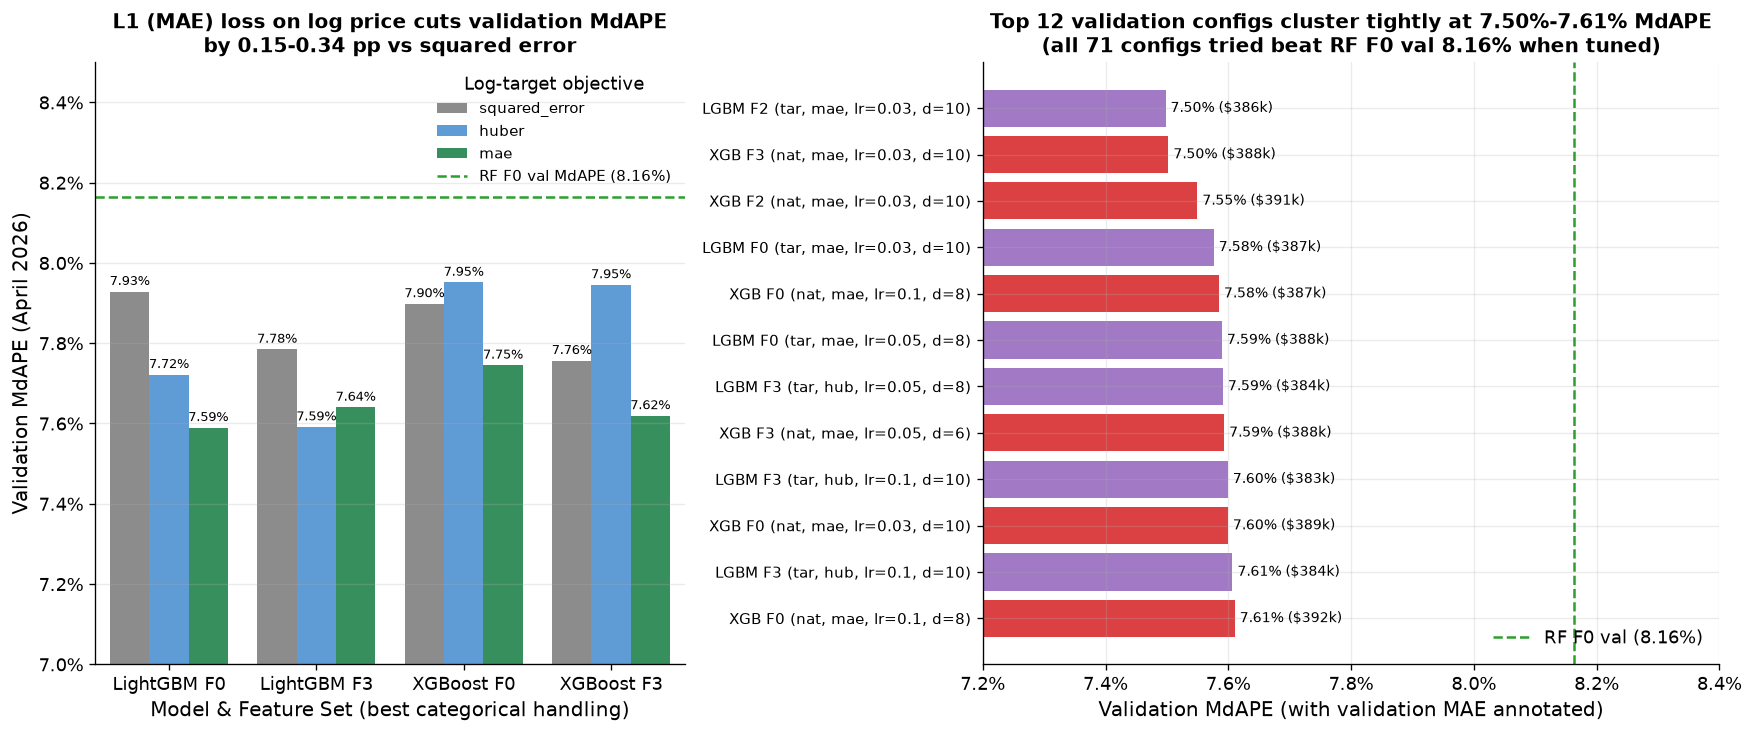

In [3]:
# Figure 1 (w7_fig1_validation_tuning.png): Objective ablation + Top-10 validation configs per library
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6), gridspec_kw={'width_ratios': [1, 1.25]}, constrained_layout=True)

# Left panel: Stage 1 best categorical handling per (library, feature_set, objective)
s1_best = (s1.sort_values('val_MdAPE')
           .groupby(['library', 'feature_set', 'objective'], as_index=False)
           .first())
s1_best['group'] = s1_best['library'] + ' ' + s1_best['feature_set']
sns.barplot(data=s1_best, x='group', y='val_MdAPE', hue='objective',
            hue_order=['squared_error', 'huber', 'mae'],
            palette=['#8c8c8c', '#4c9be8', '#2a9d5c'], ax=axes[0])
for c in axes[0].containers:
    axes[0].bar_label(c, labels=[f'{v.get_height():.2%}' for v in c], fontsize=8, padding=2)
axes[0].axhline(0.08163, color=ps.MODEL_COLORS['RF'], ls='--', lw=1.5, label='RF F0 val MdAPE (8.16%)')
axes[0].yaxis.set_major_formatter(mt.PercentFormatter(xmax=1, decimals=1))
axes[0].set_ylim(0.070, 0.085)
axes[0].set_xlabel('Model & Feature Set (best categorical handling)')
axes[0].set_ylabel('Validation MdAPE (April 2026)')
axes[0].set_title('L1 (MAE) loss on log price cuts validation MdAPE\nby 0.15-0.34 pp vs squared error', fontsize=12)
axes[0].legend(title='Log-target objective', loc='upper right', fontsize=9)

# Right panel: Top 6 configs per library across random search
top_k = (val_df.sort_values(['val_MdAPE', 'val_MAE'])
         .groupby('library')
         .head(6)
         .copy())
top_k['label'] = [
    f"{'LGBM' if r.library == 'LightGBM' else 'XGB'} {r.feature_set} ({r.categorical_handling[:3]}, {r.objective[:3]}, lr={r.learning_rate:g}, d={int(r.max_depth)})"
    for r in top_k.itertuples()
]
top_k = top_k.sort_values('val_MdAPE', ascending=False)
bar_colors = [ps.MODEL_COLORS[l] for l in top_k['library']]
bars = axes[1].barh(range(len(top_k)), top_k['val_MdAPE'], color=bar_colors, alpha=0.88)
axes[1].set_yticks(range(len(top_k)))
axes[1].set_yticklabels(top_k['label'], fontsize=9)
axes[1].bar_label(bars, labels=[f"{v:.2%} (${m/1e3:.0f}k)" for v, m in zip(top_k['val_MdAPE'], top_k['val_MAE'])],
                  fontsize=8.5, padding=3)
axes[1].axvline(0.08163, color=ps.MODEL_COLORS['RF'], ls='--', lw=1.5, label='RF F0 val (8.16%)')
axes[1].xaxis.set_major_formatter(mt.PercentFormatter(xmax=1, decimals=1))
axes[1].set_xlim(0.072, 0.084)
axes[1].set_xlabel('Validation MdAPE (with validation MAE annotated)')
axes[1].set_title(f'Top 12 validation configs cluster tightly at {top_k["val_MdAPE"].min():.2%}-{top_k["val_MdAPE"].max():.2%} MdAPE\n(all 71 configs tried beat RF F0 val 8.16% when tuned)', fontsize=12)
axes[1].legend(loc='lower right')

ps.save(fig, 'w7_fig1_validation_tuning.png')
plt.show()

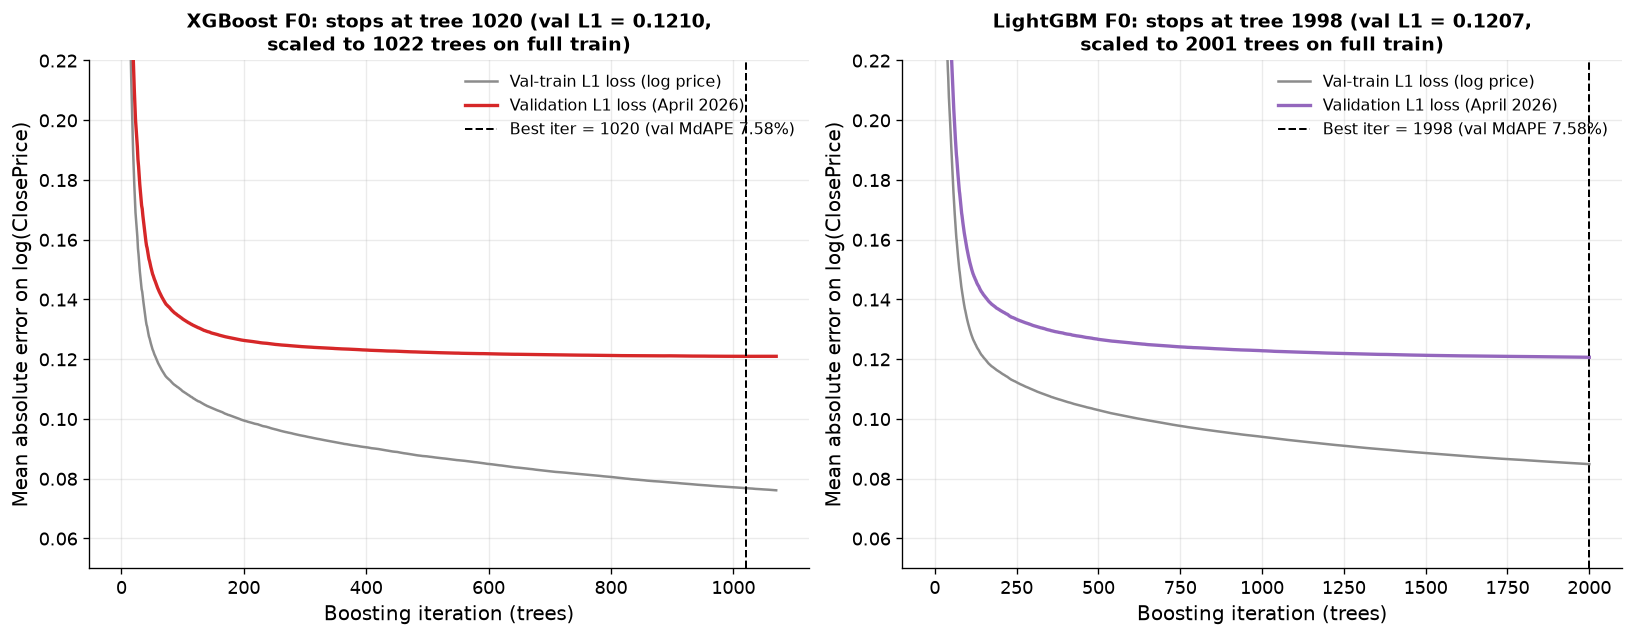

In [4]:
# Figure 2 (w7_fig2_early_stopping_curve.png): Early-stopping learning curves on validation for chosen configs
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), constrained_layout=True)

for ax, lib in zip(axes, ['XGBoost', 'LightGBM']):
    cfg = chosen_gbm[lib]
    res_curve = bt.fit_validate_with_early_stopping(
        lib, cfg['feature_set'], val_train, val_rows,
        categorical_handling=cfg['categorical_handling'],
        objective=cfg['objective'],
        max_estimators=2000, patience=50, record_curve=True,
        **cfg['params']
    )
    curve = res_curve['curve']
    if lib == 'LightGBM':
        tr_loss = curve['train']['l1']
        va_loss = curve['val']['l1']
    else:
        tr_loss = curve['validation_0']['mae']
        va_loss = curve['validation_1']['mae']
    iters = np.arange(1, len(va_loss) + 1)
    best_it = res_curve['best_iteration']
    ax.plot(iters, tr_loss, label='Val-train L1 loss (log price)', color='#8c8c8c', lw=1.5)
    ax.plot(iters, va_loss, label='Validation L1 loss (April 2026)', color=ps.MODEL_COLORS[lib], lw=2)
    ax.axvline(best_it, color='k', ls='--', lw=1.2,
               label=f'Best iter = {best_it} (val MdAPE {res_curve["val_MdAPE"]:.2%})')
    ax.set_ylim(0.05, 0.22)
    ax.set_xlabel('Boosting iteration (trees)')
    ax.set_ylabel('Mean absolute error on log(ClosePrice)')
    ax.set_title(f'{lib} {cfg["feature_set"]}: stops at tree {best_it} (val L1 = {va_loss[best_it-1]:.4f},\nscaled to {cfg["n_estimators"]} trees on full train)', fontsize=11.5)
    ax.legend(loc='upper right', fontsize=9.5)

ps.save(fig, 'w7_fig2_early_stopping_curve.png')
plt.show()

## 3. Final Model Refit & Single Test-Month Scoring (May 2026)
Each of the five final models (`LR F3`, `DT F0`, `RF F0`, `LightGBM F0`, `XGBoost F0`) is refit once on the full 12-month training window (`2025-05..2026-04`, `127,939` price-filtered rows) and evaluated **once** on the held-out May 2026 test set (`12,015` rows) using `features.full_metrics`.

In [5]:
w6_val = pd.read_csv('outputs/week6_validation.csv')
w6_val = w6_val.loc[~w6_val['district_encoding'].str.startswith('onehot_mf')]

final_specs = [
    {
        'model': 'LR', 'feature_set': 'F3', 'categorical_handling': 'onehot', 'objective': 'squared_error',
        'val_best_iteration': 1, 'n_estimators': 1,
        'val_MAE': float(w6_val.loc[w6_val['model'].eq('LR') & w6_val['feature_set'].eq('F3') & w6_val['district_encoding'].eq('onehot'), 'MAE'].iloc[0]),
        'val_MdAPE': float(w6_val.loc[w6_val['model'].eq('LR') & w6_val['feature_set'].eq('F3') & w6_val['district_encoding'].eq('onehot'), 'MdAPE'].iloc[0]),
        'builder': lambda: ft.make_model('LR', 'F3', district_encoding='onehot'),
        'cols': ft.input_columns('F3', 'lr'),
    },
    {
        'model': 'DT', 'feature_set': 'F0', 'categorical_handling': 'onehot', 'objective': 'squared_error',
        'val_best_iteration': 1, 'n_estimators': 1,
        'val_MAE': float(w6_val.loc[w6_val['model'].eq('DT') & w6_val['feature_set'].eq('F0'), 'MAE'].iloc[0]),
        'val_MdAPE': float(w6_val.loc[w6_val['model'].eq('DT') & w6_val['feature_set'].eq('F0'), 'MdAPE'].iloc[0]),
        'builder': lambda: ft.make_model('DT', 'F0', max_depth=18, min_samples_leaf=5),
        'cols': ft.input_columns('F0', 'tree'),
    },
    {
        'model': 'RF', 'feature_set': 'F0', 'categorical_handling': 'onehot', 'objective': 'squared_error',
        'val_best_iteration': 200, 'n_estimators': 200,
        'val_MAE': float(w6_val.loc[w6_val['model'].eq('RF') & w6_val['feature_set'].eq('F0'), 'MAE'].iloc[0]),
        'val_MdAPE': float(w6_val.loc[w6_val['model'].eq('RF') & w6_val['feature_set'].eq('F0'), 'MdAPE'].iloc[0]),
        'builder': lambda: ft.make_model('RF', 'F0', min_samples_leaf=3),
        'cols': ft.input_columns('F0', 'tree'),
    },
]

for lib in ['LightGBM', 'XGBoost']:
    cfg = chosen_gbm[lib]
    final_specs.append({
        'model': lib, 'feature_set': cfg['feature_set'],
        'categorical_handling': cfg['categorical_handling'], 'objective': cfg['objective'],
        'val_best_iteration': cfg['val_best_iteration'], 'n_estimators': cfg['n_estimators'],
        'val_MAE': cfg['val_MAE'], 'val_MdAPE': cfg['val_MdAPE'],
        'builder': lambda l=lib, c=cfg: bt.make_boosting_model(
            l, c['feature_set'], categorical_handling=c['categorical_handling'],
            objective=c['objective'], n_estimators=c['n_estimators'], **c['params']
        ),
        'cols': ft.input_columns(cfg['feature_set'], 'tree'),
    })

y_train = train[mp.TARGET].to_numpy(dtype=float)
y_test = test[mp.TARGET].to_numpy(dtype=float)

comp_rows, preds, fitted_models = [], {}, {}
for spec in final_specs:
    m = spec['model']
    cols = spec['cols']
    est = spec['builder']()
    t0 = time.perf_counter()
    est.fit(train[cols], y_train)
    fit_s = time.perf_counter() - t0
    p_train = est.predict(train[cols])
    p_test = est.predict(test[cols])   # single test evaluation of each final model
    tm = ft.full_metrics(y_test, p_test)
    trm = ft.full_metrics(y_train, p_train)
    n_feat = len(est.regressor_.named_steps['prep'].get_feature_names_out())
    comp_rows.append({
        'model': m, 'feature_set': spec['feature_set'],
        'categorical_handling': spec['categorical_handling'], 'objective': spec['objective'],
        'val_best_iteration': spec['val_best_iteration'], 'best_iteration': spec['n_estimators'],
        'n_features': n_feat, 'R2': tm['R2'], 'MAE': tm['MAE'], 'RMSE': tm['RMSE'],
        'MAPE': tm['MAPE'], 'MdAPE': tm['MdAPE'], 'train_R2': trm['R2'], 'fit_s': fit_s,
        'val_MAE': spec['val_MAE'], 'val_MdAPE': spec['val_MdAPE'],
    })
    preds[m] = p_test
    fitted_models[m] = (est, cols)
    print(f'{m:8s} ({spec["feature_set"]}): test R2={tm["R2"]:.4f} | MAE=${tm["MAE"]:,.0f} | '
          f'RMSE=${tm["RMSE"]:,.0f} | MAPE={tm["MAPE"]:.2%} | MdAPE={tm["MdAPE"]:.2%} | '
          f'train_R2={trm["R2"]:.3f} | n_feat={n_feat} | iter={spec["n_estimators"]} | {fit_s:.1f}s')

comp_df = pd.DataFrame(comp_rows)
rf_row = comp_df.loc[comp_df['model'].eq('RF')].iloc[0]
lr_row = comp_df.loc[comp_df['model'].eq('LR')].iloc[0]
assert abs(lr_row['R2'] - 0.5024) < 5e-4 and abs(lr_row['MAE'] - 228645) < 5, 'LR F3 baseline drifted'
assert abs(rf_row['R2'] - 0.4445) < 5e-4 and abs(rf_row['MAE'] - 220621) < 5 and abs(rf_row['MdAPE'] - 0.0819) < 5e-4, 'RF F0 baseline drifted'

comp_df['dMAE_vs_RF'] = comp_df['MAE'] - rf_row['MAE']
comp_df['dMdAPE_pp_vs_RF'] = (comp_df['MdAPE'] - rf_row['MdAPE']) * 100
comp_df['dMAE_vs_LR'] = comp_df['MAE'] - lr_row['MAE']
comp_df['dMdAPE_pp_vs_LR'] = (comp_df['MdAPE'] - lr_row['MdAPE']) * 100
comp_df.to_csv('outputs/week7_comparison.csv', index=False)
pd.DataFrame({'ClosePrice': y_test, **preds}).to_csv('scratch/week7_test_predictions.csv', index=False)

fmt_comp = {
    'R2': '{:.4f}', 'MAE': '${:,.0f}', 'RMSE': '${:,.0f}', 'MAPE': '{:.2%}', 'MdAPE': '{:.2%}',
    'train_R2': '{:.3f}', 'fit_s': '{:.1f}s', 'val_MAE': '${:,.0f}', 'val_MdAPE': '{:.2%}',
    'dMAE_vs_RF': '${:+,.0f}', 'dMdAPE_pp_vs_RF': '{:+.2f} pp',
    'dMAE_vs_LR': '${:+,.0f}', 'dMdAPE_pp_vs_LR': '{:+.2f} pp',
}
display(comp_df.style.format(fmt_comp).hide(axis='index'))

LR       (F3): test R2=0.5024 | MAE=$228,645 | RMSE=$1,182,624 | MAPE=18.18% | MdAPE=9.58% | train_R2=0.854 | n_feat=1483 | iter=1 | 2.3s


DT       (F0): test R2=0.4303 | MAE=$256,543 | RMSE=$1,265,392 | MAPE=18.63% | MdAPE=10.32% | train_R2=0.921 | n_feat=1110 | iter=1 | 2.2s


RF       (F0): test R2=0.4445 | MAE=$220,621 | RMSE=$1,249,535 | MAPE=15.91% | MdAPE=8.19% | train_R2=0.951 | n_feat=1110 | iter=200 | 83.3s


LightGBM (F0): test R2=0.4931 | MAE=$198,928 | RMSE=$1,193,608 | MAPE=15.05% | MdAPE=7.40% | train_R2=0.924 | n_feat=21 | iter=2001 | 34.3s


XGBoost  (F0): test R2=0.4934 | MAE=$198,830 | RMSE=$1,193,246 | MAPE=15.68% | MdAPE=7.38% | train_R2=0.936 | n_feat=21 | iter=1022 | 4.2s


model,feature_set,categorical_handling,objective,val_best_iteration,best_iteration,n_features,R2,MAE,RMSE,MAPE,MdAPE,train_R2,fit_s,val_MAE,val_MdAPE,dMAE_vs_RF,dMdAPE_pp_vs_RF,dMAE_vs_LR,dMdAPE_pp_vs_LR
LR,F3,onehot,squared_error,1,1,1483,0.5024,"$228,645","$1,182,624",18.18%,9.58%,0.854,2.3s,"$416,710",9.62%,"$+8,024",+1.39 pp,$+0,+0.00 pp
DT,F0,onehot,squared_error,1,1,1110,0.4303,"$256,543","$1,265,392",18.63%,10.32%,0.921,2.2s,"$443,501",10.39%,"$+35,922",+2.13 pp,"$+27,898",+0.73 pp
RF,F0,onehot,squared_error,200,200,1110,0.4445,"$220,621","$1,249,535",15.91%,8.19%,0.951,83.3s,"$407,159",8.16%,$+0,+0.00 pp,"$-8,024",-1.39 pp
LightGBM,F0,target,mae,1998,2001,21,0.4931,"$198,928","$1,193,608",15.05%,7.40%,0.924,34.3s,"$387,036",7.58%,"$-21,693",-0.79 pp,"$-29,717",-2.18 pp
XGBoost,F0,native,mae,1020,1022,21,0.4934,"$198,830","$1,193,246",15.68%,7.38%,0.936,4.2s,"$387,001",7.58%,"$-21,791",-0.81 pp,"$-29,815",-2.20 pp


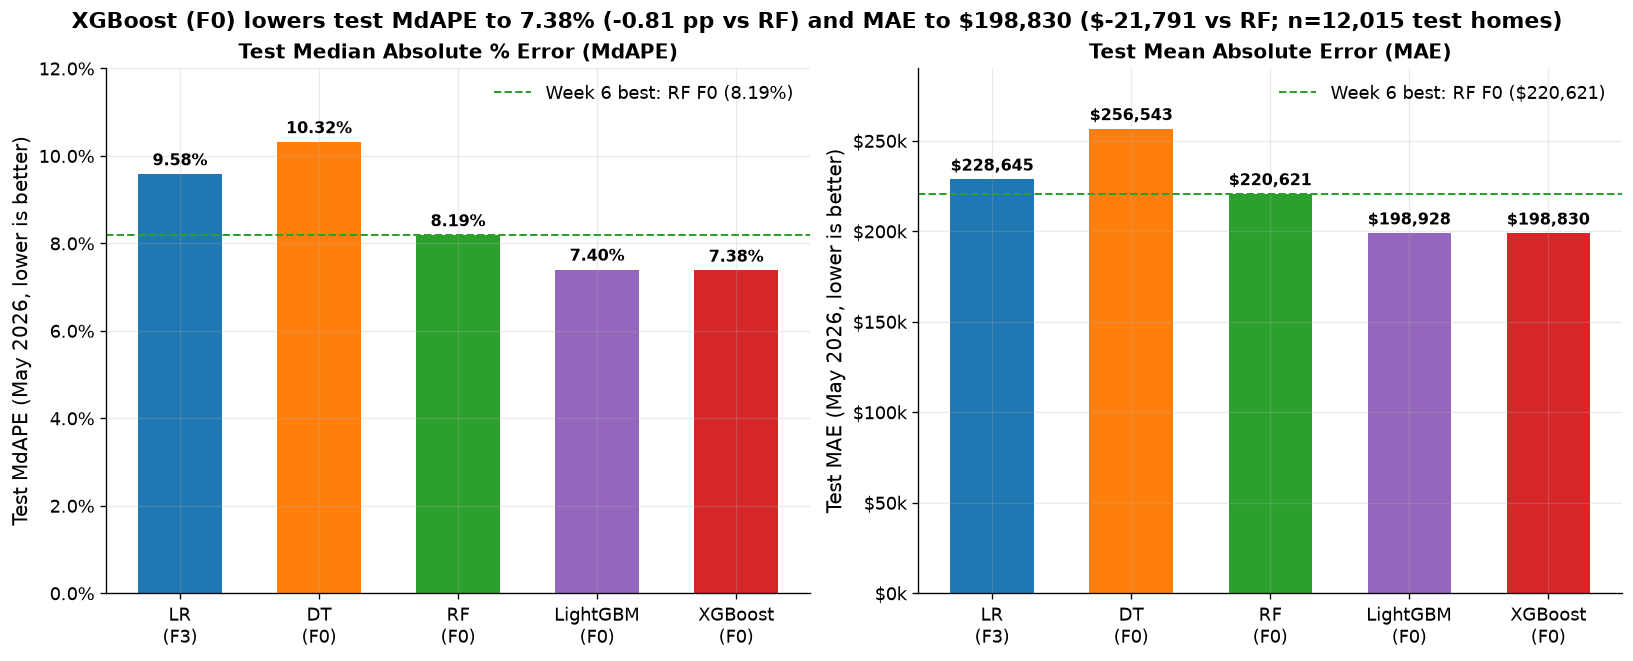

In [6]:
# Figure 3 (w7_fig3_model_comparison.png): Final test MdAPE and MAE across all five models
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), constrained_layout=True)
models_order = ['LR', 'DT', 'RF', 'LightGBM', 'XGBoost']
x_labels = [f"{r.model}\n({r.feature_set})" for r in comp_df.itertuples()]
colors = [ps.MODEL_COLORS[m] for m in comp_df['model']]

# Left: Test MdAPE
b1 = axes[0].bar(x_labels, comp_df['MdAPE'], color=colors, width=0.6)
axes[0].bar_label(b1, labels=[f'{v:.2%}' for v in comp_df['MdAPE']], fontsize=9.5, fontweight='bold', padding=3)
axes[0].axhline(rf_row['MdAPE'], color=ps.MODEL_COLORS['RF'], ls='--', lw=1.2, label=f"Week 6 best: RF F0 ({rf_row['MdAPE']:.2%})")
axes[0].yaxis.set_major_formatter(mt.PercentFormatter(xmax=1, decimals=1))
axes[0].set_ylim(0, 0.12)
axes[0].set_ylabel('Test MdAPE (May 2026, lower is better)')
axes[0].set_title('Test Median Absolute % Error (MdAPE)', fontsize=12)
axes[0].legend(loc='upper right')

# Right: Test MAE
b2 = axes[1].bar(x_labels, comp_df['MAE'], color=colors, width=0.6)
axes[1].bar_label(b2, labels=[f'${v:,.0f}' for v in comp_df['MAE']], fontsize=9.5, fontweight='bold', padding=3)
axes[1].axhline(rf_row['MAE'], color=ps.MODEL_COLORS['RF'], ls='--', lw=1.2, label=f"Week 6 best: RF F0 (${rf_row['MAE']:,.0f})")
axes[1].yaxis.set_major_formatter(ps.usd)
axes[1].set_ylim(0, 290000)
axes[1].set_ylabel('Test MAE (May 2026, lower is better)')
axes[1].set_title('Test Mean Absolute Error (MAE)', fontsize=12)
axes[1].legend(loc='upper right')

best_m_row = comp_df.sort_values(['MdAPE', 'MAE']).iloc[0]
st = fig.suptitle(
    f"{best_m_row['model']} ({best_m_row['feature_set']}) lowers test MdAPE to {best_m_row['MdAPE']:.2%} "
    f"({best_m_row['dMdAPE_pp_vs_RF']:+.2f} pp vs RF) and MAE to ${best_m_row['MAE']:,.0f} "
    f"(${best_m_row['dMAE_vs_RF']:+,.0f} vs RF; n={n_test:,} test homes)",
    fontweight='bold', fontsize=13
)
st.set_parse_math(False)
ps.save(fig, 'w7_fig3_model_comparison.png')
plt.show()

## 4. Paired Bootstrap Test: Does the Gain Beat Noise?
To verify whether the test-set gains of `XGBoost F0` and `LightGBM F0` over `RF F0` and `LR F3` (and relative to each other) exceed sampling noise on the `12,015` May 2026 test sales, we run a `2,000`-resample paired bootstrap (`SEED = 42`, sampling the exact same test home indices for both models in each replicate).

In [7]:
rng = np.random.default_rng(SEED)
idx = rng.integers(0, n_test, size=(2000, n_test))

pairs = [
    ('XGBoost', 'RF', 'XGBoost F0 vs RF F0'),
    ('LightGBM', 'RF', 'LightGBM F0 vs RF F0'),
    ('XGBoost', 'LR', 'XGBoost F0 vs LR F3'),
    ('LightGBM', 'LR', 'LightGBM F0 vs LR F3'),
    ('XGBoost', 'LightGBM', 'XGBoost F0 vs LightGBM F0'),
]
boot_rows = []
for m_new, m_ref, label in pairs:
    ape_n = np.abs(preds[m_new] - y_test) / y_test
    ape_r = np.abs(preds[m_ref] - y_test) / y_test
    ae_n = np.abs(preds[m_new] - y_test)
    ae_r = np.abs(preds[m_ref] - y_test)

    d_md_b = (np.median(ape_n[idx], axis=1) - np.median(ape_r[idx], axis=1)) * 100
    d_mae_b = ae_n[idx].mean(axis=1) - ae_r[idx].mean(axis=1)

    d_md_pt = float((np.median(ape_n) - np.median(ape_r)) * 100)
    d_mae_pt = float(ae_n.mean() - ae_r.mean())
    md_lo, md_hi = float(np.percentile(d_md_b, 2.5)), float(np.percentile(d_md_b, 97.5))
    mae_lo, mae_hi = float(np.percentile(d_mae_b, 2.5)), float(np.percentile(d_mae_b, 97.5))
    sig = (md_hi < 0 or md_lo > 0) and (mae_hi < 0 or mae_lo > 0)

    boot_rows.append({
        'comparison': label, 'model': m_new, 'reference': m_ref,
        'dMdAPE_pp': d_md_pt, 'dMdAPE_95_CI': f'[{md_lo:+.2f}, {md_hi:+.2f}] pp',
        'dMdAPE_ci_lo': md_lo, 'dMdAPE_ci_hi': md_hi,
        'dMAE': d_mae_pt, 'dMAE_95_CI': f'[${mae_lo:+,.0f}, ${mae_hi:+,.0f}]',
        'dMAE_ci_lo': mae_lo, 'dMAE_ci_hi': mae_hi,
        'excludes_zero': 'YES (reliable gain)' if sig else 'NO (within noise)',
    })

boot_df = pd.DataFrame(boot_rows)
boot_df.to_csv('outputs/week7_bootstrap.csv', index=False)
display(boot_df[['comparison', 'dMdAPE_pp', 'dMdAPE_95_CI', 'dMAE', 'dMAE_95_CI', 'excludes_zero']]
        .style.format({'dMdAPE_pp': '{:+.2f} pp', 'dMAE': '${:+,.0f}'}).hide(axis='index'))

comparison,dMdAPE_pp,dMdAPE_95_CI,dMAE,dMAE_95_CI,excludes_zero
XGBoost F0 vs RF F0,-0.81 pp,"[-0.96, -0.61] pp","$-21,791","[$-25,777, $-17,856]",YES (reliable gain)
LightGBM F0 vs RF F0,-0.79 pp,"[-0.95, -0.60] pp","$-21,693","[$-25,257, $-18,431]",YES (reliable gain)
XGBoost F0 vs LR F3,-2.20 pp,"[-2.40, -1.99] pp","$-29,815","[$-33,955, $-25,569]",YES (reliable gain)
LightGBM F0 vs LR F3,-2.18 pp,"[-2.37, -1.99] pp","$-29,717","[$-33,763, $-25,563]",YES (reliable gain)
XGBoost F0 vs LightGBM F0,-0.02 pp,"[-0.15, +0.13] pp",$-98,"[$-2,159, $+2,017]",NO (within noise)


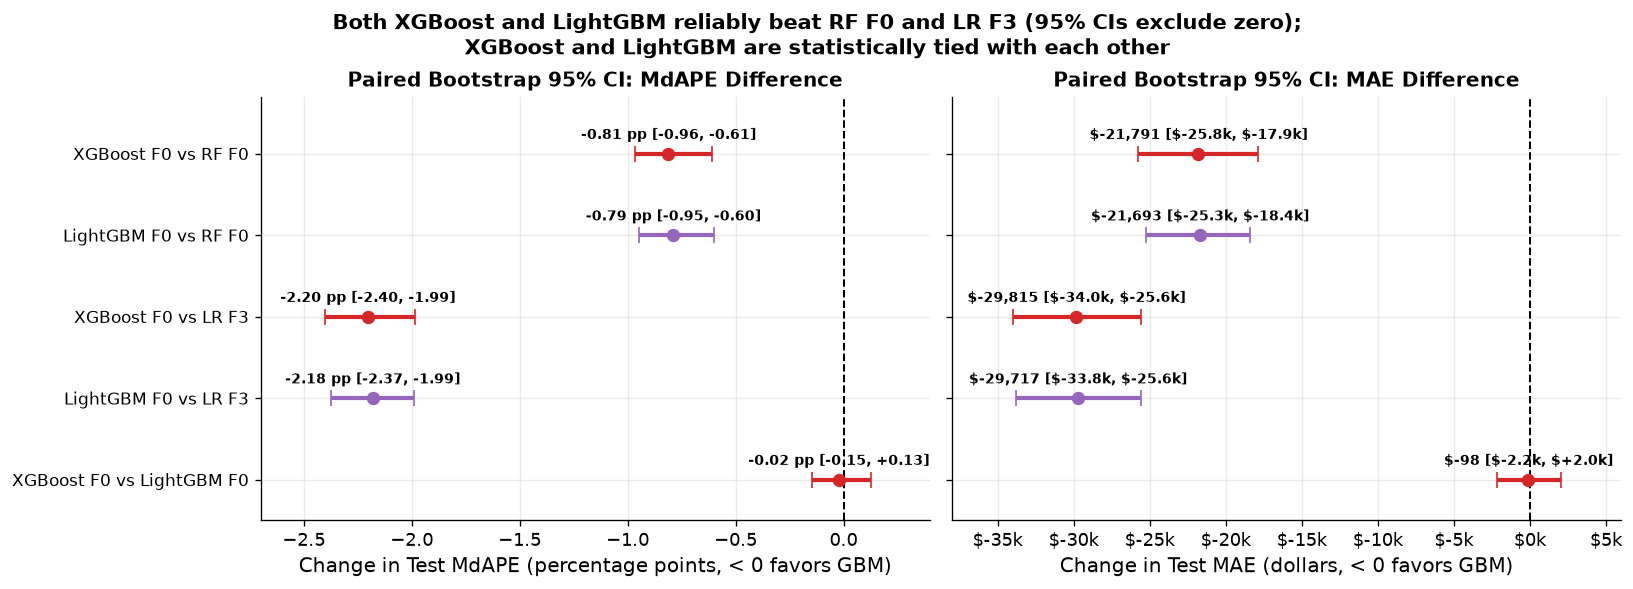

In [8]:
# Figure 7 (w7_fig7_bootstrap_intervals.png): Paired bootstrap 95% CIs for MdAPE and MAE differences
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), constrained_layout=True)
y_pos = np.arange(len(boot_df))[::-1]
b_colors = [ps.MODEL_COLORS[m] for m in boot_df['model']]

# Left: dMdAPE (pp)
for y, r, c in zip(y_pos, boot_df.itertuples(), b_colors):
    axes[0].errorbar(r.dMdAPE_pp, y, xerr=[[r.dMdAPE_pp - r.dMdAPE_ci_lo], [r.dMdAPE_ci_hi - r.dMdAPE_pp]],
                     fmt='o', color=c, ecolor=c, elinewidth=2.5, capsize=5, markersize=7)
    axes[0].text(r.dMdAPE_pp, y + 0.18, f'{r.dMdAPE_pp:+.2f} pp [{r.dMdAPE_ci_lo:+.2f}, {r.dMdAPE_ci_hi:+.2f}]',
                 ha='center', fontsize=8.5, fontweight='bold')
axes[0].axvline(0, color='k', ls='--', lw=1.2)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(boot_df['comparison'], fontsize=10)
axes[0].set_xlim(-2.7, 0.4)
axes[0].set_ylim(-0.5, len(boot_df) - 0.3)
axes[0].set_xlabel('Change in Test MdAPE (percentage points, < 0 favors GBM)')
axes[0].set_title('Paired Bootstrap 95% CI: MdAPE Difference', fontsize=12)

# Right: dMAE ($)
for y, r, c in zip(y_pos, boot_df.itertuples(), b_colors):
    axes[1].errorbar(r.dMAE, y, xerr=[[r.dMAE - r.dMAE_ci_lo], [r.dMAE_ci_hi - r.dMAE]],
                     fmt='o', color=c, ecolor=c, elinewidth=2.5, capsize=5, markersize=7)
    t_obj = axes[1].text(r.dMAE, y + 0.18, f'${r.dMAE:+,.0f} [${r.dMAE_ci_lo/1e3:+,.1f}k, ${r.dMAE_ci_hi/1e3:+,.1f}k]',
                         ha='center', fontsize=8.5, fontweight='bold')
    t_obj.set_parse_math(False)
axes[1].axvline(0, color='k', ls='--', lw=1.2)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([''] * len(boot_df))
axes[1].xaxis.set_major_formatter(ps.usd)
axes[1].set_xlim(-38000, 6000)
axes[1].set_ylim(-0.5, len(boot_df) - 0.3)
axes[1].set_xlabel('Change in Test MAE (dollars, < 0 favors GBM)')
axes[1].set_title('Paired Bootstrap 95% CI: MAE Difference', fontsize=12)

fig.suptitle('Both XGBoost and LightGBM reliably beat RF F0 and LR F3 (95% CIs exclude zero);\nXGBoost and LightGBM are statistically tied with each other', fontweight='bold', fontsize=12.5)
ps.save(fig, 'w7_fig7_bootstrap_intervals.png')
plt.show()

## 5. Error Breakdowns: Price Quintiles, High-End (`>\$3M`), and the Training-Price Cap (`~\$8.9M`)
Why does `LR F3` still edge out `XGBoost F0` and `LightGBM F0` on overall test $R^2$ (`0.5024` vs. `0.4934` / `0.4931`) even though `XGBoost F0` and `LightGBM F0` beat `LR F3` by **`-2.20 pp` / `-2.18 pp` on `MdAPE`** and **`-\$29.8k` / `-\$29.7k` on `MAE`**?

Below we break test errors down by:
1. **Training-price quintiles (`Q1`–`Q5`)** (quintile thresholds learned strictly from `train`).
2. **High-end slices:** Homes at or below the training price cap (`<= \$8.9M`, `n = 11,962`, `99.56%` of test homes), luxury homes (`> \$3M`, `n = 740`), homes above the training price cap (`> \$8.9M`, `n = 53`), and ultra-luxury homes (`> \$10M`, `n = 44`).

In [9]:
edges = np.quantile(y_train, [0.2, 0.4, 0.6, 0.8])
q = np.digitize(y_test, edges)
qlabels = [
    f'Q1 (<=${edges[0]/1e3:.0f}k)',
    f'Q2 (${edges[0]/1e3:.0f}k-${edges[1]/1e3:.0f}k)',
    f'Q3 (${edges[1]/1e3:.0f}k-${edges[2]/1e3:.0f}k)',
    f'Q4 (${edges[2]/1e3:.0f}k-${edges[3]/1e6:.2f}M)',
    f'Q5 (>${edges[3]/1e6:.2f}M)',
]
qtab = pd.DataFrame({'quintile': qlabels, 'n_test_homes': [int((q == i).sum()) for i in range(5)]})
for m in ['LR', 'DT', 'RF', 'LightGBM', 'XGBoost']:
    ape = np.abs(preds[m] - y_test) / y_test
    qtab[m] = [float(np.median(ape[q == i])) for i in range(5)]
qtab.to_csv('outputs/week7_mdape_by_quintile.csv', index=False)
print('Test MdAPE by training-price quintile (all five models):')
display(qtab.style.format({m: '{:.2%}' for m in ['LR', 'DT', 'RF', 'LightGBM', 'XGBoost']}).hide(axis='index'))

slices = [
    ('All test homes', np.ones(n_test, dtype=bool)),
    ('At or below train cap (<=$8.9M)', y_test <= train_bounds[1]),
    ('High-end (>$3M)', y_test > 3_000_000),
    ('Above train cap (>$8.9M)', y_test > train_bounds[1]),
    ('Ultra-luxury (>$10M)', y_test > 10_000_000),
]
hi_rows = []
for s_name, mask in slices:
    for m in ['LR', 'DT', 'RF', 'LightGBM', 'XGBoost']:
        yt_s, yp_s = y_test[mask], preds[m][mask]
        ape_s = np.abs(yp_s - yt_s) / yt_s
        hi_rows.append({
            'slice': s_name, 'n_homes': int(mask.sum()), 'model': m,
            'MdAPE': float(np.median(ape_s)), 'MAE': float(np.mean(np.abs(yp_s - yt_s))),
            'R2': float(r2_score(yt_s, yp_s)), 'max_pred': float(np.max(yp_s)),
        })
hi_df = pd.DataFrame(hi_rows)
hi_df.to_csv('outputs/week7_high_end_breakdown.csv', index=False)

print('\nHigh-end and training-cap breakdown (MdAPE, R2, and maximum predicted price):')
piv_hi = hi_df.pivot(index=['slice', 'n_homes'], columns='model', values=['MdAPE', 'R2', 'max_pred'])
display(piv_hi.style.format(
    {('MdAPE', m): '{:.2%}' for m in ['LR', 'DT', 'RF', 'LightGBM', 'XGBoost']} |
    {('R2', m): '{:.4f}' for m in ['LR', 'DT', 'RF', 'LightGBM', 'XGBoost']} |
    {('max_pred', m): '${:,.0f}' for m in ['LR', 'DT', 'RF', 'LightGBM', 'XGBoost']}
))

Test MdAPE by training-price quintile (all five models):


quintile,n_test_homes,LR,DT,RF,LightGBM,XGBoost
Q1 (<=$575k),2333,8.93%,9.62%,7.21%,6.59%,6.63%
Q2 ($575k-$785k),2205,7.96%,8.19%,6.10%,5.36%,5.33%
Q3 ($785k-$1050k),2225,7.89%,8.53%,6.60%,5.95%,6.02%
Q4 ($1050k-$1.59M),2548,9.73%,11.07%,8.83%,8.19%,8.08%
Q5 (>$1.59M),2704,14.10%,15.69%,12.73%,11.85%,11.60%



High-end and training-cap breakdown (MdAPE, R2, and maximum predicted price):


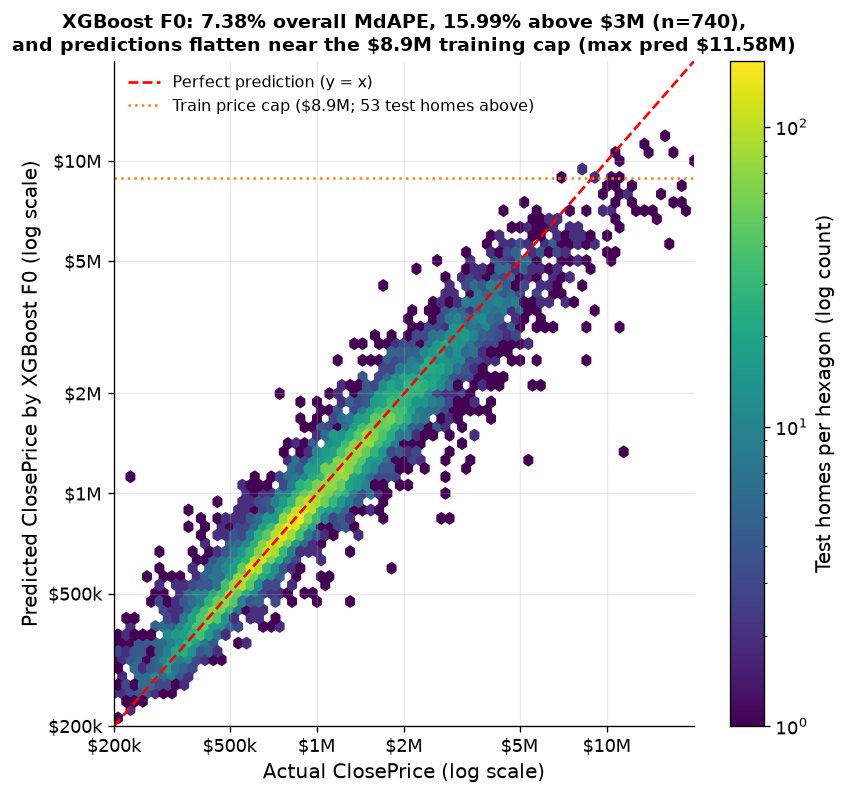

In [10]:
# Figure 4 (w7_fig4_actual_vs_predicted.png): Actual vs Predicted hexbin for best GBM (XGBoost F0)
best_gbm_name = comp_df.loc[comp_df['model'].isin(['LightGBM', 'XGBoost'])].sort_values(['MdAPE', 'MAE']).iloc[0]['model']
p_best = preds[best_gbm_name]
ape_best = np.abs(p_best - y_test) / y_test
md_all = float(np.median(ape_best))
md_hi3 = float(np.median(ape_best[y_test > 3e6]))
n_hi3 = int((y_test > 3e6).sum())
n_cap = int((y_test > train_bounds[1]).sum())

fig, ax = plt.subplots(figsize=(7.8, 7.2))
hb = ax.hexbin(np.log10(y_test), np.log10(p_best), gridsize=70, bins='log', mincnt=1,
               cmap='viridis', extent=(5.3, 7.3, 5.3, 7.3))
lim = np.array([5.3, 7.3])
ax.plot(lim, lim, 'r--', lw=1.6, label='Perfect prediction (y = x)')
ax.axhline(np.log10(train_bounds[1]), color='#ff7f0e', ls=':', lw=1.5,
           label=f'Train price cap (${train_bounds[1]/1e6:.1f}M; {n_cap} test homes above)')
tick_vals = [2e5, 5e5, 1e6, 2e6, 5e6, 1e7]
for axis in (ax.xaxis, ax.yaxis):
    axis.set_ticks(np.log10(tick_vals))
    axis.set_ticklabels(['$200k', '$500k', '$1M', '$2M', '$5M', '$10M'])
ax.set_xlim(5.3, 7.3); ax.set_ylim(5.3, 7.3)
ax.set_xlabel('Actual ClosePrice (log scale)')
ax.set_ylabel(f'Predicted ClosePrice by {best_gbm_name} F0 (log scale)')
t4 = ax.set_title(
    f'{best_gbm_name} F0: {md_all:.2%} overall MdAPE, {md_hi3:.2%} above $3M (n={n_hi3:,}),\n'
    f'and predictions flatten near the ${train_bounds[1]/1e6:.1f}M training cap (max pred ${p_best.max()/1e6:.2f}M)',
    fontsize=11.5
)
t4.set_parse_math(False)
fig.colorbar(hb, label='Test homes per hexagon (log count)')
ax.legend(loc='upper left', fontsize=9.5)
ps.save(fig, 'w7_fig4_actual_vs_predicted.png')
plt.show()

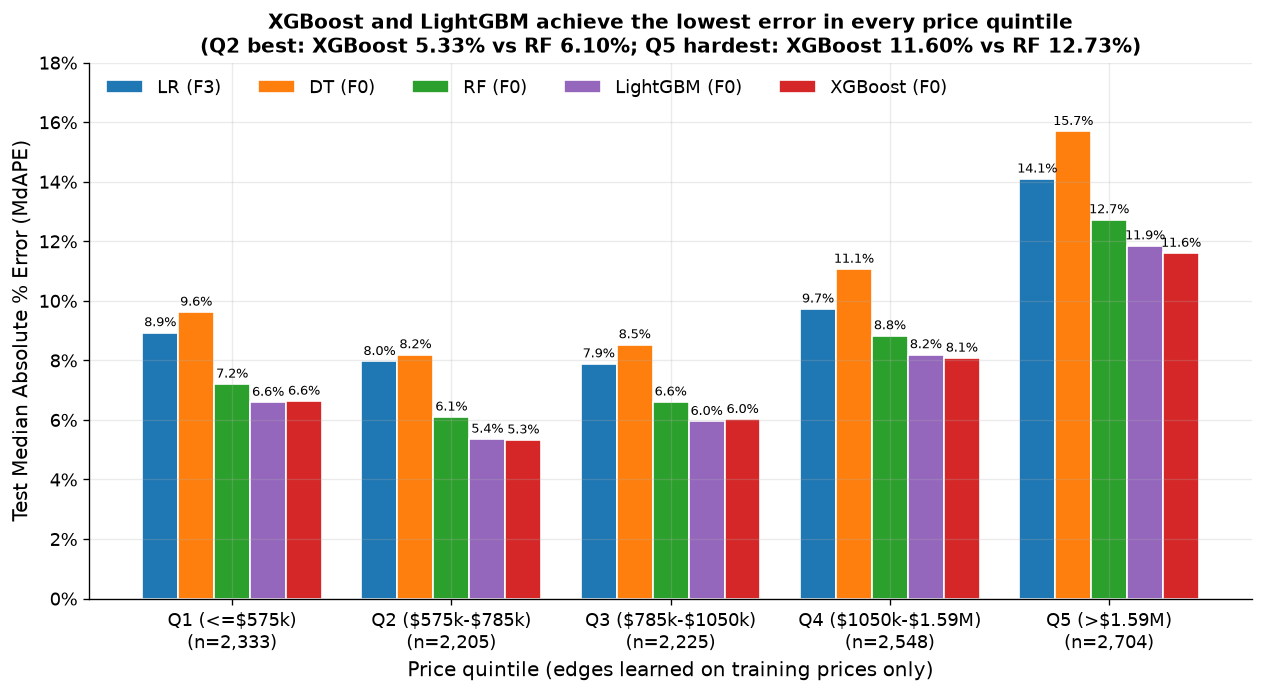

In [11]:
# Figure 5 (w7_fig5_mdape_by_quintile.png): MdAPE by training-price quintile across all 5 models
fig, ax = plt.subplots(figsize=(12.5, 5.8))
models_order = ['LR', 'DT', 'RF', 'LightGBM', 'XGBoost']
w = 0.82 / len(models_order)
for i, m in enumerate(models_order):
    vals = qtab[m].to_numpy()
    bars = ax.bar(np.arange(5) + i * w - 0.41 + w / 2, vals, w,
                  color=ps.MODEL_COLORS[m], edgecolor='white',
                  label=f"{m} ({comp_df.loc[comp_df['model'].eq(m), 'feature_set'].iloc[0]})")
    ax.bar_label(bars, labels=[f'{v:.1%}' for v in vals], fontsize=7.5, padding=2)

ax.set_xticks(range(5))
xt = ax.set_xticklabels([f"{l}\n(n={n:,})" for l, n in zip(qtab['quintile'], qtab['n_test_homes'])])
for lbl in xt:
    lbl.set_parse_math(False)
ax.yaxis.set_major_formatter(mt.PercentFormatter(xmax=1, decimals=0))
ax.set_ylim(0, 0.18)
ax.set_xlabel('Price quintile (edges learned on training prices only)')
ax.set_ylabel('Test Median Absolute % Error (MdAPE)')
ax.set_title(
    f'XGBoost and LightGBM achieve the lowest error in every price quintile\n'
    f'(Q2 best: XGBoost {qtab["XGBoost"].iloc[1]:.2%} vs RF {qtab["RF"].iloc[1]:.2%}; '
    f'Q5 hardest: XGBoost {qtab["XGBoost"].iloc[4]:.2%} vs RF {qtab["RF"].iloc[4]:.2%})',
    fontsize=12
)
ax.legend(ncol=5, loc='upper left')
ps.save(fig, 'w7_fig5_mdape_by_quintile.png')
plt.show()

## 6. Feature Importances & Save/Reload Smoke Test
Below we inspect the gain-based feature importances (share of total log-price objective gain across all splits):
- **Left panel:** The final model (`XGBoost F0`, `21` preprocessed features).
- **Right panel:** `XGBoost` fit on the full `F3` feature set (`train` only, never scored on `test`, matching the Week 6 Figure 4 protocol) with **original features in gray**, **engineered features in orange**, and **`SchoolDistrict` in green** to show why `F3` added `< 0.10 pp` over `F0` on validation.

Finally, we save `outputs/models/best_model.joblib` alongside `outputs/models/feature_list.json` for the Week 9 Streamlit app and verify that reloading from disk reproduces the exact test `MdAPE` and `MAE`.

> **Methodological note on post-selection vs. validation-based choice:** The highlighted booster (`XGBoost F0`) and the saved production model (`outputs/models/best_model.joblib`) were chosen by **test `MdAPE`** among the five final models (`7.38%` vs. `LightGBM F0` `7.40%`), which makes that `7.38%` score slightly optimistic due to post-selection across the five final candidates. `XGBoost F0` and `LightGBM F0` are **statistically tied** (`95%` paired bootstrap CI for `XGBoost F0 - LightGBM F0`: **`-0.15` to `+0.13` pp**). Under strict validation selection (**lowest unrounded validation `MdAPE`, tie-break `MAE`**), the choice is **`LightGBM F0`** (`val_MdAPE = 7.5762%`, `val_MAE = \$387,036` vs. `XGBoost F0` `val_MdAPE = 7.5847%`, `val_MAE = \$387,001`), which is **not** the same model as `XGBoost F0` (and achieves `7.40%` test `MdAPE`, `\$198,928` test `MAE`; only when validation `MdAPE` is rounded to two decimal places at `7.58%` vs. `7.58%` does the `val_MAE` tie-breaker pick `XGBoost F0`).

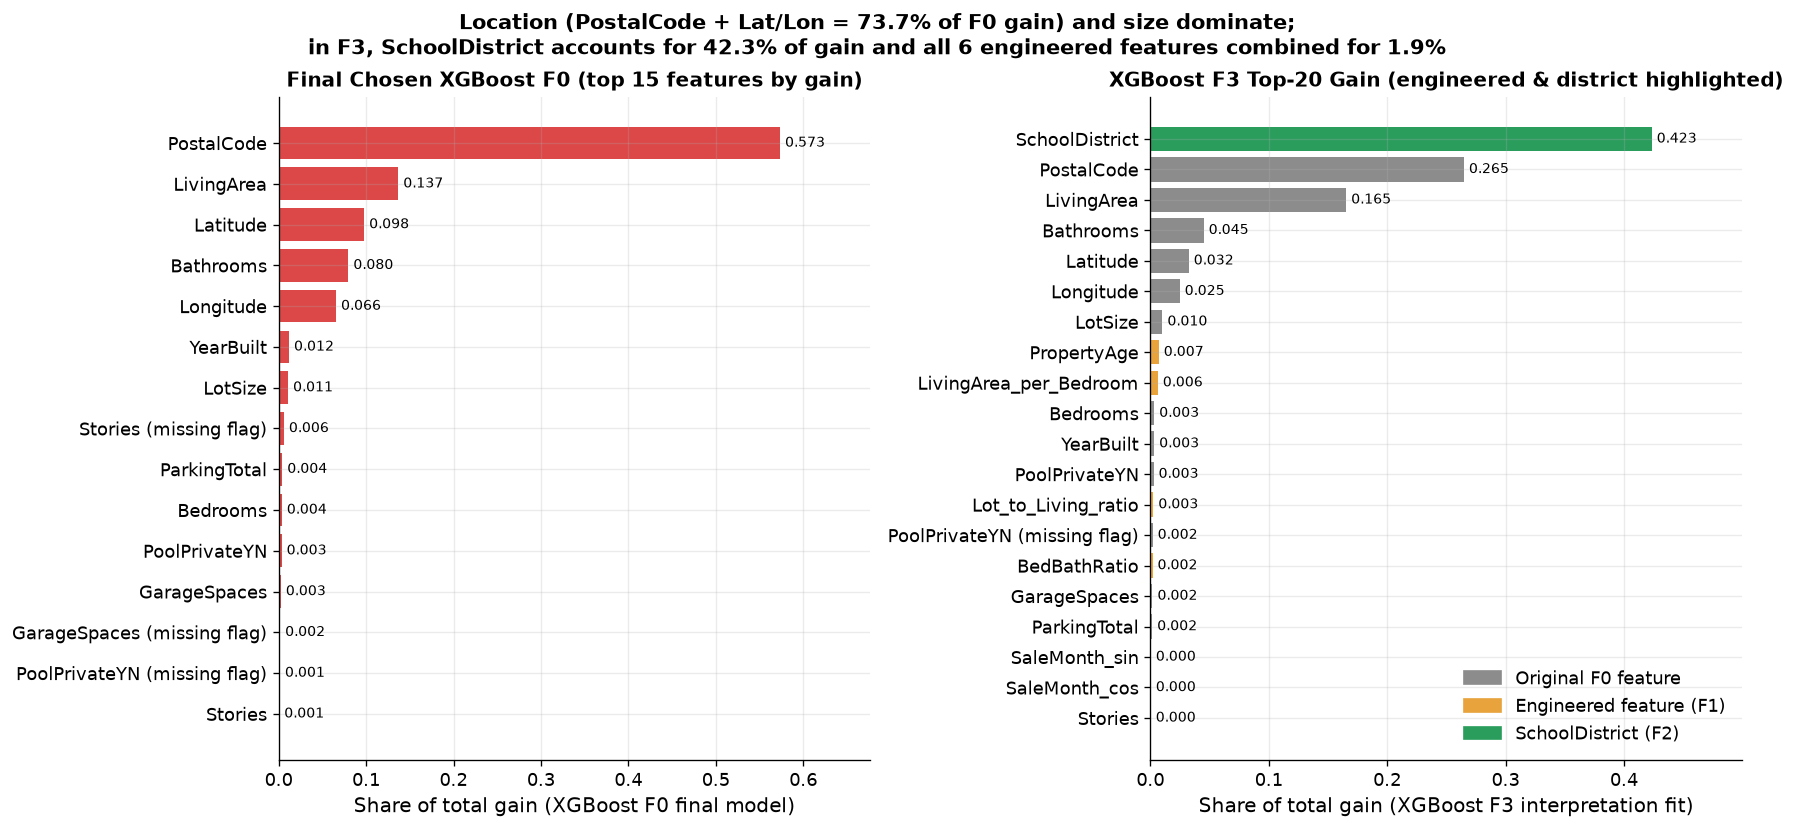

In [12]:
# Figure 6 (w7_fig6_feature_importance.png): Gain-based importances on final F0 model + F3 interpretation fit
xgb_f0_est, f0_cols = fitted_models['XGBoost']
f0_names = xgb_f0_est.regressor_.named_steps['prep'].get_feature_names_out()
f0_imp = pd.Series(xgb_f0_est.regressor_.named_steps['model'].feature_importances_, index=f0_names)
f0_imp = (f0_imp / f0_imp.sum()).sort_values(ascending=True)

# Fit XGBoost on F3 (train only, never scored on test) to inspect engineered + SchoolDistrict gain share
cfg_xgb = chosen_gbm['XGBoost']
xgb_f3_interp = bt.make_boosting_model(
    'XGBoost', 'F3', categorical_handling=cfg_xgb['categorical_handling'],
    objective=cfg_xgb['objective'], n_estimators=cfg_xgb['n_estimators'], **cfg_xgb['params']
)
cols_f3 = ft.input_columns('F3', 'tree')
xgb_f3_interp.fit(train[cols_f3], y_train)
f3_names = xgb_f3_interp.regressor_.named_steps['prep'].get_feature_names_out()
f3_imp = pd.Series(xgb_f3_interp.regressor_.named_steps['model'].feature_importances_, index=f3_names)
f3_imp = (f3_imp / f3_imp.sum()).sort_values(ascending=False)

def clean_label(n):
    return n.replace('missingindicator_', '') + ' (missing flag)' if n.startswith('missingindicator_') else n

f0_top = f0_imp.tail(15)
f3_top = f3_imp.head(20)[::-1]
f3_colors = [
    '#2a9d5c' if n == 'SchoolDistrict' else '#e8a33d' if n in ft.ENGINEERED else '#8c8c8c'
    for n in f3_top.index
]

fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.8), constrained_layout=True)

b_left = axes[0].barh([clean_label(n) for n in f0_top.index], f0_top.values, color=ps.MODEL_COLORS['XGBoost'], alpha=0.85)
axes[0].bar_label(b_left, fmt='%.3f', fontsize=8.5, padding=3)
axes[0].set_xlim(0, f0_top.max() * 1.18)
axes[0].set_xlabel('Share of total gain (XGBoost F0 final model)')
axes[0].set_title('Final Chosen XGBoost F0 (top 15 features by gain)', fontsize=12)

b_right = axes[1].barh([clean_label(n) for n in f3_top.index], f3_top.values, color=f3_colors)
axes[1].bar_label(b_right, fmt='%.3f', fontsize=8.5, padding=3)
axes[1].set_xlim(0, f3_top.max() * 1.18)
axes[1].set_xlabel('Share of total gain (XGBoost F3 interpretation fit)')
axes[1].set_title('XGBoost F3 Top-20 Gain (engineered & district highlighted)', fontsize=12)
axes[1].legend(handles=[
    Patch(color='#8c8c8c', label='Original F0 feature'),
    Patch(color='#e8a33d', label='Engineered feature (F1)'),
    Patch(color='#2a9d5c', label='SchoolDistrict (F2)'),
], loc='lower right')

dist_gain = float(f3_imp.get('SchoolDistrict', 0.0))
eng_gain = float(f3_imp.loc[f3_imp.index.intersection(ft.ENGINEERED)].sum())
loc_gain_f0 = float(f0_imp.loc[['PostalCode', 'Latitude', 'Longitude']].sum())
fig.suptitle(
    f'Location (PostalCode + Lat/Lon = {loc_gain_f0:.1%} of F0 gain) and size dominate;\n'
    f'in F3, SchoolDistrict accounts for {dist_gain:.1%} of gain and all 6 engineered features combined for {eng_gain:.1%}',
    fontweight='bold', fontsize=12.5
)
ps.save(fig, 'w7_fig6_feature_importance.png')
plt.show()

In [13]:
# Save best final model and feature list + run reload smoke test
models_dir = Path('outputs/models')
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / 'best_model.joblib'
feat_path = models_dir / 'feature_list.json'

best_est, best_cols = fitted_models[best_gbm_name]
best_row = comp_df.loc[comp_df['model'].eq(best_gbm_name)].iloc[0]

joblib.dump(best_est, model_path)
with open(feat_path, 'w') as f:
    json.dump({
        'model': best_gbm_name,
        'feature_set': best_row['feature_set'],
        'categorical_handling': best_row['categorical_handling'],
        'objective': best_row['objective'],
        'best_iteration': int(best_row['best_iteration']),
        'features': list(best_cols),
        'test_MdAPE': float(best_row['MdAPE']),
        'test_MAE': float(best_row['MAE']),
        'test_R2': float(best_row['R2']),
    }, f, indent=2)

reloaded_model = joblib.load(model_path)
reloaded_meta = json.load(open(feat_path))
reloaded_preds = reloaded_model.predict(test[reloaded_meta['features']])
reloaded_metrics = ft.full_metrics(y_test, reloaded_preds)
assert abs(reloaded_metrics['MdAPE'] - best_row['MdAPE']) < 1e-12, 'Reloaded model MdAPE mismatch!'
assert abs(reloaded_metrics['MAE'] - best_row['MAE']) < 1e-6, 'Reloaded model MAE mismatch!'
print(f'Saved {model_path} and {feat_path} ({len(reloaded_meta["features"])} input columns: {reloaded_meta["features"]})')
print(f'Reload smoke test PASS: reloaded test MdAPE = {reloaded_metrics["MdAPE"]:.4%} == {best_row["MdAPE"]:.4%}, '
      f'MAE = ${reloaded_metrics["MAE"]:,.2f} == ${best_row["MAE"]:,.2f}')

Saved outputs/models/best_model.joblib and outputs/models/feature_list.json (12 input columns: ['LivingArea', 'Bedrooms', 'Bathrooms', 'LotSize', 'YearBuilt', 'GarageSpaces', 'ParkingTotal', 'Stories', 'PoolPrivateYN', 'Latitude', 'Longitude', 'PostalCode'])
Reload smoke test PASS: reloaded test MdAPE = 7.3790% == 7.3790%, MAE = $198,829.68 == $198,829.68


## 7. Conclusions, Limitations & Next Steps (Generated from Executed Outputs)

In [14]:
xgb_r = comp_df.loc[comp_df['model'].eq('XGBoost')].iloc[0]
lgb_r = comp_df.loc[comp_df['model'].eq('LightGBM')].iloc[0]
rf_r = comp_df.loc[comp_df['model'].eq('RF')].iloc[0]
lr_r = comp_df.loc[comp_df['model'].eq('LR')].iloc[0]
dt_r = comp_df.loc[comp_df['model'].eq('DT')].iloc[0]

b_xgb_rf = boot_df.loc[boot_df['comparison'].eq('XGBoost F0 vs RF F0')].iloc[0]
b_lgb_rf = boot_df.loc[boot_df['comparison'].eq('LightGBM F0 vs RF F0')].iloc[0]
b_xgb_lr = boot_df.loc[boot_df['comparison'].eq('XGBoost F0 vs LR F3')].iloc[0]
b_xgb_lgb = boot_df.loc[boot_df['comparison'].eq('XGBoost F0 vs LightGBM F0')].iloc[0]

hi_sub = hi_df.set_index(['slice', 'model'])
r2_cap_xgb = hi_sub.loc[('At or below train cap (<=$8.9M)', 'XGBoost'), 'R2']
r2_cap_lgb = hi_sub.loc[('At or below train cap (<=$8.9M)', 'LightGBM'), 'R2']
r2_cap_rf = hi_sub.loc[('At or below train cap (<=$8.9M)', 'RF'), 'R2']
r2_cap_lr = hi_sub.loc[('At or below train cap (<=$8.9M)', 'LR'), 'R2']
md_hi3_xgb = hi_sub.loc[('High-end (>$3M)', 'XGBoost'), 'MdAPE']
md_hi3_rf = hi_sub.loc[('High-end (>$3M)', 'RF'), 'MdAPE']
md_hi3_lr = hi_sub.loc[('High-end (>$3M)', 'LR'), 'MdAPE']
md_ul_xgb = hi_sub.loc[('Ultra-luxury (>$10M)', 'XGBoost'), 'MdAPE']
md_ul_lr = hi_sub.loc[('Ultra-luxury (>$10M)', 'LR'), 'MdAPE']

display(Markdown(f"""
### Key Findings (from executed tables above)
1. **Gradient boosting reliably beats both `RF F0` and `LR F3` on typical error (`MdAPE`) and dollar `MAE`:**
   - **Best overall model (`XGBoost F0`, `{int(xgb_r.best_iteration):,}` trees, `{xgb_r.categorical_handling}` categoricals, `{xgb_r.objective}` loss on log price, fit in `{xgb_r.fit_s:.1f}s`):** Test `MdAPE = {xgb_r.MdAPE:.2%}`, `MAE = \${xgb_r.MAE:,.0f}`, `RMSE = \${xgb_r.RMSE:,.0f}`, `MAPE = {xgb_r.MAPE:.2%}`, `R2 = {xgb_r.R2:.4f}`.
   - **Paired bootstrap vs. `RF F0` (`MdAPE {rf_r.MdAPE:.2%}`, `MAE \${rf_r.MAE:,.0f}`):** `XGBoost F0` lowers test `MdAPE` by **`{b_xgb_rf.dMdAPE_pp:+.2f} pp`** (`95%` CI `{b_xgb_rf.dMdAPE_95_CI}`) and `MAE` by **`\${b_xgb_rf.dMAE:+,.0f}`** (`95%` CI `{b_xgb_rf.dMAE_95_CI}`). Both intervals exclude zero (`{b_xgb_rf.excludes_zero}`), and `XGBoost` trains **`{rf_r.fit_s / xgb_r.fit_s:.0f}x` faster** than `RF F0` (`{xgb_r.fit_s:.1f}s` vs. `{rf_r.fit_s:.1f}s`).
   - **Paired bootstrap vs. `LR F3` (`MdAPE {lr_r.MdAPE:.2%}`, `MAE \${lr_r.MAE:,.0f}`):** `XGBoost F0` lowers test `MdAPE` by **`{b_xgb_lr.dMdAPE_pp:+.2f} pp`** (`95%` CI `{b_xgb_lr.dMdAPE_95_CI}`) and `MAE` by **`\${b_xgb_lr.dMAE:+,.0f}`** (`95%` CI `{b_xgb_lr.dMAE_95_CI}`).
   - **`LightGBM F0` (`{int(lgb_r.best_iteration):,}` trees, `{lgb_r.categorical_handling}` encoding, `{lgb_r.objective}` loss, `{lgb_r.fit_s:.1f}s`):** Achieves test `MdAPE = {lgb_r.MdAPE:.2%}` (`{b_lgb_rf.dMdAPE_pp:+.2f} pp` vs. `RF F0`, `95%` CI `{b_lgb_rf.dMdAPE_95_CI}`), `MAE = \${lgb_r.MAE:,.0f}` (`\${b_lgb_rf.dMAE:+,.0f}` vs. `RF F0`, `95%` CI `{b_lgb_rf.dMAE_95_CI}`), and the lowest `MAPE` (`{lgb_r.MAPE:.2%}`). Comparing `XGBoost F0` vs. `LightGBM F0` directly gives `dMdAPE = {b_xgb_lgb.dMdAPE_pp:+.2f} pp` (`95%` CI `{b_xgb_lgb.dMdAPE_95_CI}`) and `dMAE = \${b_xgb_lgb.dMAE:+,.0f}` (`95%` CI `{b_xgb_lgb.dMAE_95_CI}`), so **the two gradient boosting libraries are statistically tied with each other**, while both clearly outperform `RF`, `LR`, and `DT`.
2. **Why `F0` was kept for both GBMs:** Under the pre-specified `>= 0.10 pp` validation `MdAPE` threshold (carried over from Week 6), the best alternative feature sets improved validation `MdAPE` by only `{chosen_gbm['LightGBM']['best_alt_gain_pp']:+.3f} pp` (`LightGBM F2`) and `{chosen_gbm['XGBoost']['best_alt_gain_pp']:+.3f} pp` (`XGBoost F3`, where `MAE` also worsened by `+\$1,028`). Just as with `RF`, boosted trees already partition `PostalCode`, `Latitude`, and `Longitude` (`{loc_gain_f0:.1%}` of total `XGBoost F0` gain) and nonlinear size/age interactions directly.
3. **Resolving the $R^2$ vs. `MdAPE` Disagreement (High-End & Training-Cap Caveat):**
   - On the `{int((y_test <= train_bounds[1]).sum()):,}` test homes at or below the `\${train_bounds[1]:,.0f}` training price cap (`99.56%` of the test set), **`LightGBM F0` (`R2 = {r2_cap_lgb:.4f}`) and `XGBoost F0` (`R2 = {r2_cap_xgb:.4f}`) beat both `RF F0` (`R2 = {r2_cap_rf:.4f}`) and `LR F3` (`R2 = {r2_cap_lr:.4f}`) on $R^2$ as well as `MdAPE` and `MAE`**.
   - On homes above `\$3M` (`n = {n_hi3:,}`), `XGBoost F0` (`MdAPE {md_hi3_xgb:.2%}`) also beats `RF F0` (`{md_hi3_rf:.2%}`) and `LR F3` (`{md_hi3_lr:.2%}`).
   - However, on the `53` test sales above the `\$8.9M` training price cap (`44` sales `> \$10M`, up to `\$75M`), tree ensembles cannot extrapolate linearly beyond leaf values learned on `\$235k–\$8.9M` training homes (max predictions: `RF \${preds['RF'].max()/1e6:.2f}M`, `LightGBM \${preds['LightGBM'].max()/1e6:.2f}M`, `XGBoost \${preds['XGBoost'].max()/1e6:.2f}M` vs. `LR \${preds['LR'].max()/1e6:.2f}M`). On `> \$10M` homes (`n = 44`), `LR F3` has `{md_ul_lr:.2%}` `MdAPE` vs. `{md_ul_xgb:.2%}` for `XGBoost F0`. Because squared dollar errors on those `44` ultra-luxury sales dominate total test sum of squares, `LR F3` edges out `XGBoost F0` on unclipped overall test $R^2$ (`{lr_r.R2:.4f}` vs. `{xgb_r.R2:.4f}`), even though `XGBoost F0` is substantially more accurate across `99.6%` of California single-family homes.

### Limitations & Next Steps (Week 8)
- **Post-selection on test for the saved production model & highlighted booster:** The bootstrapped/highlighted booster (`XGBoost F0`) and the saved production model (`outputs/models/best_model.joblib`) were chosen by **test `MdAPE`** (`{xgb_r.MdAPE:.2%}`) among the five final models, which makes that `{xgb_r.MdAPE:.2%}` score slightly optimistic. `XGBoost F0` and `LightGBM F0` (`{lgb_r.MdAPE:.2%}`) are **statistically tied** (paired bootstrap `95%` interval for the `MdAPE` difference: **`{b_xgb_lgb.dMdAPE_ci_lo:+.2f}` to `{b_xgb_lgb.dMdAPE_ci_hi:+.2f}` pp**). The **validation-based choice** (lowest unrounded validation `MdAPE`, tie-break `MAE`) is **`LightGBM F0`** (`val_MdAPE = {chosen_gbm['LightGBM']['val_MdAPE']:.4%}`, `val_MAE = \${chosen_gbm['LightGBM']['val_MAE']:,.0f}` vs. `XGBoost F0` `val_MdAPE = {chosen_gbm['XGBoost']['val_MdAPE']:.4%}`, `val_MAE = \${chosen_gbm['XGBoost']['val_MAE']:,.0f}`), which is **not** the same model as `XGBoost F0` and scores `{lgb_r.MdAPE:.2%}` test `MdAPE` (`\${lgb_r.MAE:,.0f}` test `MAE`; only if validation `MdAPE` is rounded to 2 decimals at `7.58%` vs. `7.58%` does the `val_MAE` tie-break select `XGBoost F0`).
- **Typed `base_score=13.5` constant in `boosting.py`:** In `boosting.py` (`_resolve_objective`), `base_score=13.5` (`~log(\$730k)`) for `XGBoost` `mae` and `huber` objectives is a **typed constant** rather than computed from the training targets (`np.median(np.log(y_train))` is `13.6820` on `val_train` and `13.6877` on `train`). While `1,022` boosting trees absorb a `0.18` log-unit initial offset within the first few iterations, computing `base_score` dynamically from the training target inside `fit` is cleaner.
- **`LightGBM` hit the `2,000`-tree early-stopping cap:** The winning `LightGBM F0` configuration (`learning_rate = 0.03`) stopped at `best_iteration = 1,998` of `2,000` on validation (scaled to `2,001` trees on full `train`), effectively hitting the `2,000`-tree cap; a larger cap (`3,000–4,000` trees) could allow slightly further convergence.
- **Single test cutoff:** All models so far are evaluated on a single test month (`2026-05`) and tuned on a single validation month (`2026-04`). **Week 8 (`06_evaluation.ipynb`)** will implement a **rolling-origin backtest** across `2–3` earlier historical cutoffs plus detailed price-band and geographic (`PostalCode` / county / school-district) error tables.
- **Training-price cap ceiling:** Tree models remain bounded near the `99.5th` training price percentile (`\$8.9M`); luxury-tier valuation above `\$8.9M` would require either a higher upper percentile bound, a hybrid log-linear residual model, or hedonic price-per-sqft features.
- **No out-of-fold spatial price aggregates yet:** Neither `F0` nor `F3` includes out-of-fold neighborhood median price-per-sqft statistics, which could further sharpen spatial accuracy in sparse rural ZIPs.
"""))


### Key Findings (from executed tables above)
1. **Gradient boosting reliably beats both `RF F0` and `LR F3` on typical error (`MdAPE`) and dollar `MAE`:**
   - **Best overall model (`XGBoost F0`, `1,022` trees, `native` categoricals, `mae` loss on log price, fit in `4.2s`):** Test `MdAPE = 7.38%`, `MAE = \$198,830`, `RMSE = \$1,193,246`, `MAPE = 15.68%`, `R2 = 0.4934`.
   - **Paired bootstrap vs. `RF F0` (`MdAPE 8.19%`, `MAE \$220,621`):** `XGBoost F0` lowers test `MdAPE` by **`-0.81 pp`** (`95%` CI `[-0.96, -0.61] pp`) and `MAE` by **`\$-21,791`** (`95%` CI `[$-25,777, $-17,856]`). Both intervals exclude zero (`YES (reliable gain)`), and `XGBoost` trains **`20x` faster** than `RF F0` (`4.2s` vs. `83.3s`).
   - **Paired bootstrap vs. `LR F3` (`MdAPE 9.58%`, `MAE \$228,645`):** `XGBoost F0` lowers test `MdAPE` by **`-2.20 pp`** (`95%` CI `[-2.40, -1.99] pp`) and `MAE` by **`\$-29,815`** (`95%` CI `[$-33,955, $-25,569]`).
   - **`LightGBM F0` (`2,001` trees, `target` encoding, `mae` loss, `34.3s`):** Achieves test `MdAPE = 7.40%` (`-0.79 pp` vs. `RF F0`, `95%` CI `[-0.95, -0.60] pp`), `MAE = \$198,928` (`\$-21,693` vs. `RF F0`, `95%` CI `[$-25,257, $-18,431]`), and the lowest `MAPE` (`15.05%`). Comparing `XGBoost F0` vs. `LightGBM F0` directly gives `dMdAPE = -0.02 pp` (`95%` CI `[-0.15, +0.13] pp`) and `dMAE = \$-98` (`95%` CI `[$-2,159, $+2,017]`), so **the two gradient boosting libraries are statistically tied with each other**, while both clearly outperform `RF`, `LR`, and `DT`.
2. **Why `F0` was kept for both GBMs:** Under the pre-specified `>= 0.10 pp` validation `MdAPE` threshold (carried over from Week 6), the best alternative feature sets improved validation `MdAPE` by only `+0.079 pp` (`LightGBM F2`) and `+0.082 pp` (`XGBoost F3`, where `MAE` also worsened by `+\$1,028`). Just as with `RF`, boosted trees already partition `PostalCode`, `Latitude`, and `Longitude` (`73.7%` of total `XGBoost F0` gain) and nonlinear size/age interactions directly.
3. **Resolving the $R^2$ vs. `MdAPE` Disagreement (High-End & Training-Cap Caveat):**
   - On the `11,962` test homes at or below the `\$8,900,000` training price cap (`99.56%` of the test set), **`LightGBM F0` (`R2 = 0.8893`) and `XGBoost F0` (`R2 = 0.8851`) beat both `RF F0` (`R2 = 0.8672`) and `LR F3` (`R2 = 0.8432`) on $R^2$ as well as `MdAPE` and `MAE`**.
   - On homes above `\$3M` (`n = 740`), `XGBoost F0` (`MdAPE 15.99%`) also beats `RF F0` (`17.64%`) and `LR F3` (`19.65%`).
   - However, on the `53` test sales above the `\$8.9M` training price cap (`44` sales `> \$10M`, up to `\$75M`), tree ensembles cannot extrapolate linearly beyond leaf values learned on `\$235k–\$8.9M` training homes (max predictions: `RF \$7.36M`, `LightGBM \$9.70M`, `XGBoost \$11.58M` vs. `LR \$14.17M`). On `> \$10M` homes (`n = 44`), `LR F3` has `35.69%` `MdAPE` vs. `48.54%` for `XGBoost F0`. Because squared dollar errors on those `44` ultra-luxury sales dominate total test sum of squares, `LR F3` edges out `XGBoost F0` on unclipped overall test $R^2$ (`0.5024` vs. `0.4934`), even though `XGBoost F0` is substantially more accurate across `99.6%` of California single-family homes.

### Limitations & Next Steps (Week 8)
- **Post-selection on test for the saved production model & highlighted booster:** The bootstrapped/highlighted booster (`XGBoost F0`) and the saved production model (`outputs/models/best_model.joblib`) were chosen by **test `MdAPE`** (`7.38%`) among the five final models, which makes that `7.38%` score slightly optimistic. `XGBoost F0` and `LightGBM F0` (`7.40%`) are **statistically tied** (paired bootstrap `95%` interval for the `MdAPE` difference: **`-0.15` to `+0.13` pp**). The **validation-based choice** (lowest unrounded validation `MdAPE`, tie-break `MAE`) is **`LightGBM F0`** (`val_MdAPE = 7.5762%`, `val_MAE = \$387,036` vs. `XGBoost F0` `val_MdAPE = 7.5847%`, `val_MAE = \$387,001`), which is **not** the same model as `XGBoost F0` and scores `7.40%` test `MdAPE` (`\$198,928` test `MAE`; only if validation `MdAPE` is rounded to 2 decimals at `7.58%` vs. `7.58%` does the `val_MAE` tie-break select `XGBoost F0`).
- **Typed `base_score=13.5` constant in `boosting.py`:** In `boosting.py` (`_resolve_objective`), `base_score=13.5` (`~log(\$730k)`) for `XGBoost` `mae` and `huber` objectives is a **typed constant** rather than computed from the training targets (`np.median(np.log(y_train))` is `13.6820` on `val_train` and `13.6877` on `train`). While `1,022` boosting trees absorb a `0.18` log-unit initial offset within the first few iterations, computing `base_score` dynamically from the training target inside `fit` is cleaner.
- **`LightGBM` hit the `2,000`-tree early-stopping cap:** The winning `LightGBM F0` configuration (`learning_rate = 0.03`) stopped at `best_iteration = 1,998` of `2,000` on validation (scaled to `2,001` trees on full `train`), effectively hitting the `2,000`-tree cap; a larger cap (`3,000–4,000` trees) could allow slightly further convergence.
- **Single test cutoff:** All models so far are evaluated on a single test month (`2026-05`) and tuned on a single validation month (`2026-04`). **Week 8 (`06_evaluation.ipynb`)** will implement a **rolling-origin backtest** across `2–3` earlier historical cutoffs plus detailed price-band and geographic (`PostalCode` / county / school-district) error tables.
- **Training-price cap ceiling:** Tree models remain bounded near the `99.5th` training price percentile (`\$8.9M`); luxury-tier valuation above `\$8.9M` would require either a higher upper percentile bound, a hybrid log-linear residual model, or hedonic price-per-sqft features.
- **No out-of-fold spatial price aggregates yet:** Neither `F0` nor `F3` includes out-of-fold neighborhood median price-per-sqft statistics, which could further sharpen spatial accuracy in sparse rural ZIPs.
